# task 1 -> direct preference optimization

## imports

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#the scripts use paths relative to the repo root (configs/, data/, results/), so the notebook runs from there
if not Path('configs').exists():
    os.chdir('..')

from common.data import load_yaml, read_jsonl, repo_path

## global env variables ->

In [2]:
#papermill overrides these two for the smoke test, the defaults are the real run
CONFIG = 'configs/dpo.yaml'
RUN_SCRIPTS = True #False -> only rebuild the tables and figures from results already on disk

In [3]:
# Parameters
CONFIG = "configs/dpo.yaml"


In [4]:
cfg = load_yaml(CONFIG)
RESULTS = repo_path(cfg['results_dir'])
FIGURES = RESULTS / 'figures'
STANDARD = cfg['standard_output']

BETAS = [float(beta) for beta in cfg['betas']]
BETA_RUNS = [f'beta_{beta:g}' for beta in BETAS]
ALL_RUNS = ['base', 'standard'] + BETA_RUNS + ['length_balanced'] #base = the untrained reference policy
TRAINED_RUNS = ALL_RUNS[1:]

#one fixed colour per model, the same in every figure. base is the reference so it stays neutral grey
COLORS = {'base': '#52514e', 'standard': '#2a78d6', 'length_balanced': '#eb6834',
          BETA_RUNS[0]: '#1baf7a', BETA_RUNS[1]: '#eda100', BETA_RUNS[2]: '#e87ba4'}
STRATA = ['preferred_longer', 'length_matched', 'rejected_longer']

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2})


def run(command):
    #runs one of the release's entry points as its own process, exactly as it would be typed in a terminal.
    #each script loads its own models and writes its results to disk, nothing is passed through notebook state
    if RUN_SCRIPTS:
        get_ipython().system(command)
        assert get_ipython().user_ns['_exit_code'] == 0, f'failed -> {command}'


def load_result(name):
    return json.loads((RESULTS / name).read_text())

## standard dpo ->

one epoch on the fixed preference set from the common initialization, then the held-out evaluation. the untrained base policy goes through the same evaluation as the reference row

In [5]:
run(f'python -m task1_dpo.train --config {CONFIG} --run-name standard --output {STANDARD}')

[standard] beta 0.1  pairs 1446  dropped 54  optimizer steps 91  trainable params 1,089,536 of 1,544,803,840


[standard] step   10  loss 0.6942  acc 0.375  margin -0.020  grad 2.104


[standard] step   20  loss 0.6870  acc 0.625  margin +0.129  grad 2.091


[standard] step   30  loss 0.6836  acc 0.625  margin +0.198  grad 2.498


[standard] step   40  loss 0.6936  acc 0.688  margin +0.006  grad 2.038


...

[standard] step   70  loss 0.6949  acc 0.562  margin -0.001  grad 2.188


[standard] step   80  loss 0.6815  acc 0.688  margin +0.285  grad 2.206


[standard] step   90  loss 0.7083  acc 0.562  margin -0.232  grad 2.375


[standard] step   91  loss 0.6200  acc 0.833  margin +1.581  grad 1.560


[standard] done in 9.4 min, adapter saved to /root/pa2/outputs/task1_dpo/standard


In [6]:
run(f'python -m task1_dpo.evaluate --config {CONFIG} --name base')
run(f'python -m task1_dpo.evaluate --config {CONFIG} --adapter {STANDARD} --name standard')

[eval base] adapter None  beta 0.1  held-out pairs 290


  generated 16/290


  generated 32/290


  generated 48/290


  generated 64/290


...

  generated 16/80


  generated 32/80


  generated 48/80


  generated 64/80


  generated 80/80
[eval standard] acc 0.631  loss 0.6743  kl -0.0002  reward 1.381  length 157.1  word-limit 0.36


## regularization strength study ->

three short forks from the original initialization, only beta changes

In [7]:
run(f'python -m task1_dpo.ablate_beta --config {CONFIG}')

Required beta values: [0.03, 0.1, 0.3]
Short-run examples per condition: 600


[beta_0.03] beta 0.03  pairs 600  dropped 54  optimizer steps 38  trainable params 1,089,536 of 1,544,803,840


[beta_0.03] step   10  loss 0.6922  acc 0.812  margin +0.064  grad 0.580


[beta_0.03] step   20  loss 0.6912  acc 0.688  margin +0.130  grad 0.589


[beta_0.03] step   30  loss 0.6939  acc 0.625  margin -0.047  grad 0.624


...

  generated 16/80


  generated 32/80


  generated 48/80


  generated 64/80


  generated 80/80
[eval beta_0.3] acc 0.614  loss 0.6776  kl -0.0002  reward 1.322  length 154.7  word-limit 0.49


## length confounding study ->

one more model on the length-balanced pairs, then both models on the length-stratified held-out set

In [8]:
run(f'python -m task1_dpo.analyze_length --config {CONFIG}')

Length-balanced train rows: 1500
Length-stratified eval rows: 246


[length_balanced] beta 0.1  pairs 1442  dropped 58  optimizer steps 91  trainable params 1,089,536 of 1,544,803,840


[length_balanced] step   10  loss 0.6915  acc 0.625  margin +0.034  grad 1.491


[length_balanced] step   20  loss 0.6958  acc 0.500  margin -0.051  grad 2.289


[length_balanced] step   30  loss 0.6861  acc 0.688  margin +0.144  grad 1.732


...

  generated 48/80


  generated 64/80


  generated 80/80


[eval length_balanced] acc 0.607  loss 0.6752  kl 0.0025  reward 1.355  length 154.0  word-limit 0.46


          model          stratum  n_pairs  preference_accuracy  margin_mean  dpo_loss  corr_margin_vs_length_gap
       standard preferred_longer       78             0.474359    -0.078238  0.699643                        NaN
       standard   length_matched       80             0.600000     0.212694  0.684383                        NaN
       standard  rejected_longer       79             0.670886     0.674308  0.662890                        NaN
       standard              all      237             0.582278     0.270816  0.682241                  -0.179149
length_balanced preferred_longer       78             0.448718    -0.461069  0.721009                        NaN
length_balanced   length_matched       80             0.612500     0.360294  0.677896                        NaN
length_balanced  rejected_longer       79             0.759494     1.477841  0.627576                        NaN
length_balanced              all      237             0.607595     0.462488  0.675312           

## dpo summary results

In [9]:
#one row per condition. the budget columns are there because the standard run and the beta forks are NOT matched ->
#standard and length_balanced see every usable pair once, each beta fork only the first short_ablation_examples
FIGURES.mkdir(parents=True, exist_ok=True)

rows = []
for name in ALL_RUNS:
    ev = load_result(f'eval_{name}.json')
    train = load_result(f'train_summary_{name}.json') if name != 'base' else {}
    rows.append({
        'model': name,
        'beta': ev['beta'] if name != 'base' else np.nan,
        'train_pairs': train.get('n_pairs', 0),
        'optimizer_steps': train.get('optimizer_steps', 0),
        'heldout_dpo_loss': ev['heldout_dpo_loss'],
        #the base policy IS the reference, so its margin is exactly 0 and its accuracy is 0 by definition, not by failure
        'preference_accuracy': ev['heldout_preference_accuracy'] if name != 'base' else np.nan,
        'kl_token': ev['kl_token_mean'],
        'kl_sequence': ev['kl_sequence_mean'],
        'reward_mean': ev['reward_mean'],
        'length_mean': ev['length_mean'],
        'length_std': ev['length_std'],
        'length_iqr': ev['length_iqr'],
        'truncation_rate': ev['truncation_rate'],
        'word_limit_compliance': ev['word_limit']['compliance_rate'],
        'train_minutes': train.get('wall_clock_s', 0) / 60,
        'peak_vram_gb': train.get('peak_vram_gb'),
    })

summary = pd.DataFrame(rows)
summary.to_csv(RESULTS / 'dpo_summary.csv', index=False)
display(summary.round(4))

,model,beta,train_pairs,optimizer_steps,heldout_dpo_loss,preference_accuracy,kl_token,kl_sequence,reward_mean,length_mean,length_std,length_iqr,truncation_rate,word_limit_compliance,train_minutes,peak_vram_gb
0,base,NaN,0,0,0.6931,NaN,0.0000,0.0000,1.3435,153.9483,103.1484,212.0,0.4069,0.4875,0.0000,NaN
1,standard,0.10,1446,91,0.6743,0.6310,-0.0002,-0.0292,1.3807,157.0828,104.2615,213.5,0.4448,0.3625,9.4028,6.6583
2,beta_0.03,0.03,600,38,0.6910,0.6276,-0.0002,-0.0272,1.3275,154.8965,104.5494,216.0,0.4241,0.4750,3.8525,6.6558
3,beta_0.1,0.10,600,38,0.6865,0.6069,-0.0002,-0.0306,1.3286,154.5724,104.9931,216.0,0.4379,0.4625,4.1292,6.6562
4,beta_0.3,0.30,600,38,0.6776,0.6138,-0.0002,-0.0370,1.3216,154.6931,104.7447,216.0,0.4345,0.4875,3.8324,6.6562
5,length_balanced,0.10,1442,91,0.6752,0.6069,0.0025,0.3856,1.3546,154.0103,104.8894,217.0,0.4345,0.4625,9.3416,6.6557


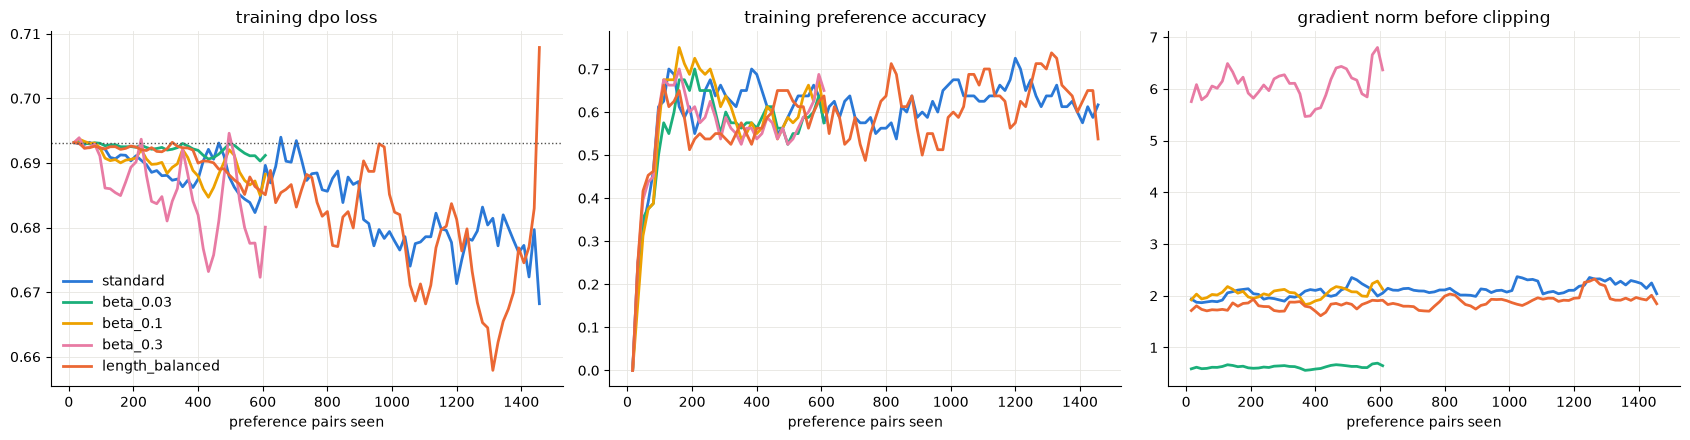

In [10]:
#training curves, one line per trained run. x is in pairs seen rather than steps, so the short forks and the
#full runs sit on a common axis
logs = {name: pd.DataFrame(read_jsonl(RESULTS / f'train_log_{name}.jsonl')) for name in TRAINED_RUNS}
effective_batch = int(cfg['batch_size']) * int(cfg['grad_accum_steps'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for axis, column, title in zip(axes, ['loss', 'acc', 'grad_norm'],
                               ['training dpo loss', 'training preference accuracy', 'gradient norm before clipping']):
    for name, log in logs.items():
        #rolling mean over 5 optimizer steps, a single step of 16 pairs is too noisy to read
        axis.plot(log['step'] * effective_batch, log[column].rolling(5, min_periods=1).mean(), color=COLORS[name], label=name)
    axis.set_title(title)
    axis.set_xlabel('preference pairs seen')
axes[0].axhline(np.log(2), color='#52514e', linestyle=':', linewidth=1) #log 2 = the loss at initialization, margin 0
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'training_curves.png', dpi=200)
plt.show()

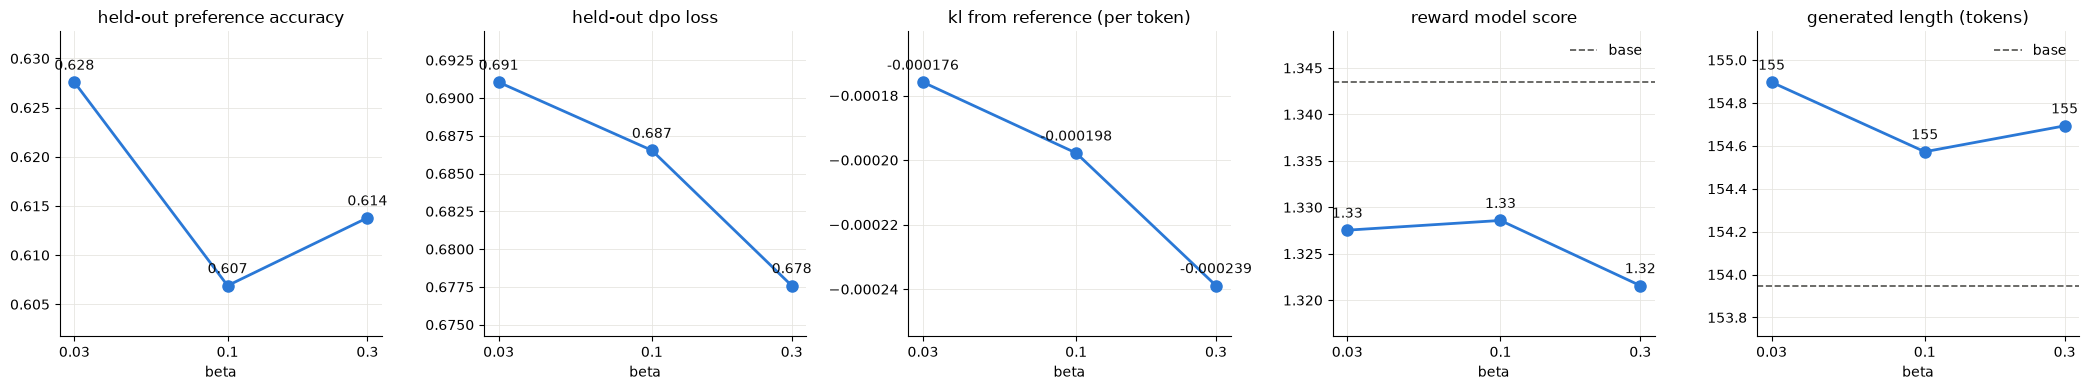

In [11]:
#the beta trade-off. one small panel per metric (they live on different scales, so no shared or double axis),
#beta on a log axis since the three values are spaced by ~3x
beta_frame = summary[summary['model'].isin(BETA_RUNS)].sort_values('beta')
panels = [('preference_accuracy', 'held-out preference accuracy'), ('heldout_dpo_loss', 'held-out dpo loss'),
          ('kl_token', 'kl from reference (per token)'), ('reward_mean', 'reward model score'),
          ('length_mean', 'generated length (tokens)')]

fig, axes = plt.subplots(1, len(panels), figsize=(21, 4))
base_row = summary[summary['model'] == 'base'].iloc[0]
for axis, (column, title) in zip(axes, panels):
    axis.plot(beta_frame['beta'], beta_frame[column], color=COLORS['standard'], marker='o', markersize=8)
    for beta, value in zip(beta_frame['beta'], beta_frame[column]):
        axis.annotate(f'{value:.3g}', (beta, value), textcoords='offset points', xytext=(0, 9), ha='center', color='#0b0b0b')
    if column in ('reward_mean', 'length_mean'): #the untrained policy as the reference level, where it is meaningful
        axis.axhline(base_row[column], color=COLORS['base'], linestyle='--', linewidth=1.2, label='base')
        axis.legend(frameon=False)
    axis.ticklabel_format(axis='y', useOffset=False) #plain tick values, no '+6.93e-1' offset notation
    axis.set_xscale('log')
    axis.set_xticks(BETAS, [f'{beta:g}' for beta in BETAS])
    axis.minorticks_off()
    axis.set_xlabel('beta')
    axis.set_title(title)
    axis.margins(y=0.25)
fig.tight_layout()
fig.savefig(FIGURES / 'beta_tradeoff.png', dpi=200)
plt.show()

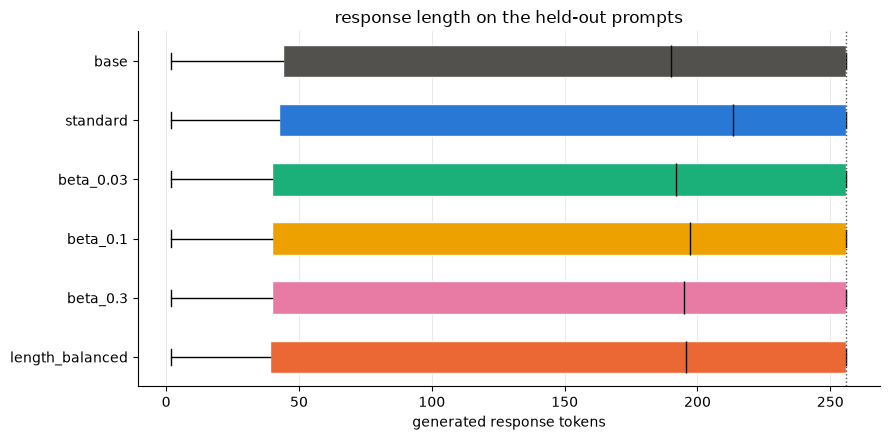

In [12]:
#generated length distribution per model on the held-out prompts, same prompts and decoding for every box
generations = {name: pd.DataFrame(read_jsonl(RESULTS / f'eval_{name}_generations.jsonl')) for name in ALL_RUNS}

fig, axis = plt.subplots(figsize=(9, 4.5))
boxes = axis.boxplot([generations[name]['response_tokens'] for name in ALL_RUNS], orientation='horizontal', patch_artist=True,
                     widths=0.55, medianprops={'color': '#0b0b0b'}, flierprops={'markersize': 3})
for box, name in zip(boxes['boxes'], ALL_RUNS):
    box.set_facecolor(COLORS[name])
    box.set_edgecolor('#fcfcfb')
axis.set_yticks(range(1, len(ALL_RUNS) + 1), ALL_RUNS)
axis.invert_yaxis()
axis.axvline(int(cfg['max_generation_tokens']), color='#52514e', linestyle=':', linewidth=1) #the generation cap
axis.set_xlabel('generated response tokens')
axis.set_title('response length on the held-out prompts')
axis.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIGURES / 'length_distribution.png', dpi=200)
plt.show()

## length confounding diagnostics

,n_pairs,frac_chosen_longer,mean_word_gap_chosen_minus_rejected,median_word_gap
standard_train,1500.0,0.553,29.426,10.0
length_balanced_train,1500.0,0.478,2.491,0.0


,model,stratum,n_pairs,preference_accuracy,margin_mean,dpo_loss,corr_margin_vs_length_gap
0,standard,preferred_longer,78,0.4744,-0.0782,0.6996,NaN
1,standard,length_matched,80,0.6000,0.2127,0.6844,NaN
2,standard,rejected_longer,79,0.6709,0.6743,0.6629,NaN
3,standard,all,237,0.5823,0.2708,0.6822,-0.1791
4,length_balanced,preferred_longer,78,0.4487,-0.4611,0.7210,NaN
5,length_balanced,length_matched,80,0.6125,0.3603,0.6779,NaN
6,length_balanced,rejected_longer,79,0.7595,1.4778,0.6276,NaN
7,length_balanced,all,237,0.6076,0.4625,0.6753,-0.3570


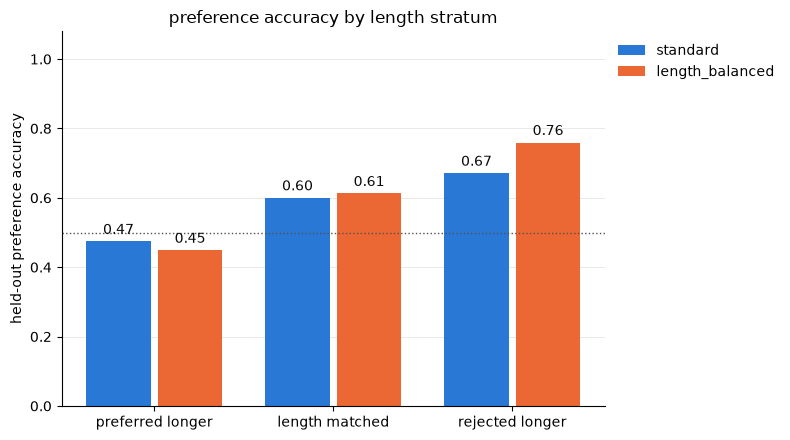

In [13]:
#dataset side -> how tied length and preference are in the two training files, before any model is involved
display(pd.DataFrame(load_result('length_dataset_diagnostics.json')).T.round(3))

#model side -> preference accuracy per stratum for the standard and the length-balanced model
strata = pd.read_csv(RESULTS / 'length_strata_accuracy.csv')
display(strata.round(4))

accuracy = strata[strata['stratum'].isin(STRATA)].pivot(index='stratum', columns='model', values='preference_accuracy').loc[STRATA]

fig, axis = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(STRATA))
for offset, name in zip([-0.2, 0.2], ['standard', 'length_balanced']):
    bars = axis.bar(positions + offset, accuracy[name], width=0.36, color=COLORS[name], label=name)
    axis.bar_label(bars, fmt='%.2f', padding=3, color='#0b0b0b')
axis.axhline(0.5, color='#52514e', linestyle=':', linewidth=1) #a coin flip
axis.set_xticks(positions, [stratum.replace('_', ' ') for stratum in STRATA])
axis.set_ylim(0, 1.08)
axis.set_ylabel('held-out preference accuracy')
axis.set_title('preference accuracy by length stratum')
axis.grid(axis='x', visible=False)
axis.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0)) #outside the plot, clear of the bars
fig.tight_layout()
fig.savefig(FIGURES / 'length_strata_accuracy.png', dpi=200)
plt.show()

In [14]:
#generated length and explicit word-limit compliance on the common prompt set, base included as the reference
word_limit = {name: pd.DataFrame(read_jsonl(RESULTS / f'eval_{name}_word_limit.jsonl')) for name in ALL_RUNS}

compare = pd.DataFrame([{
    'model': name,
    'heldout_length_mean': generations[name]['response_tokens'].mean(),
    'heldout_length_std': generations[name]['response_tokens'].std(ddof=0),
    'word_limit_compliance': word_limit[name]['compliant'].mean(),
    'word_limit_words_mean': word_limit[name]['words'].mean(),
    'word_limit_tokens_mean': word_limit[name]['response_tokens'].mean(),
} for name in ['base', 'standard', 'length_balanced']])
compare.to_csv(RESULTS / 'length_generation_compare_with_base.csv', index=False)
display(compare.round(3))

#compliance per prompt, the limit differs from prompt to prompt (25 to 45 words)
per_prompt = pd.DataFrame({name: word_limit[name].groupby('prompt_id')['compliant'].mean()
                           for name in ['base', 'standard', 'length_balanced']})
display(per_prompt.round(2))

,model,heldout_length_mean,heldout_length_std,word_limit_compliance,word_limit_words_mean,word_limit_tokens_mean
0,base,153.948,103.148,0.488,41.650,48.962
1,standard,157.083,104.261,0.362,43.500,51.300
2,length_balanced,154.010,104.889,0.462,40.312,47.738


,base,standard,length_balanced
prompt_id,,,
wl01,1.00,0.75,0.88
wl02,0.00,0.00,0.00
wl03,1.00,0.88,0.88
wl04,0.25,0.25,0.00
wl05,0.12,0.12,0.38
wl06,0.62,0.12,0.75
wl07,0.00,0.00,0.12
wl08,0.88,0.62,0.75
wl09,0.88,0.88,0.88


## qualitative candidates ->

shortlists to read through and pick the report examples from, nothing here is selected automatically

In [15]:
pd.set_option('display.max_colwidth', 400)

#(i) preference/reward versus quality -> prompts where the dpo response scores clearly higher on the reward model
#than the base response to the same prompt, sorted by the gain. the largest gains that come with a much longer or
#truncated response are the first places to look for a higher score without a better answer
paired = generations['base'].merge(generations['standard'], on='prompt_id', suffixes=('_base', '_dpo'))
paired['reward_gain'] = paired['reward_dpo'] - paired['reward_base']
paired['length_change'] = paired['response_tokens_dpo'] - paired['response_tokens_base']
columns = ['prompt_id', 'reward_base', 'reward_dpo', 'reward_gain', 'response_tokens_base', 'response_tokens_dpo',
           'truncated_dpo', 'prompt_base', 'response_base', 'response_dpo']
display(paired.sort_values('reward_gain', ascending=False)[columns].head(8))
print('correlation of reward gain with length change', round(paired['reward_gain'].corr(paired['length_change']), 3))

,prompt_id,reward_base,reward_dpo,reward_gain,response_tokens_base,response_tokens_dpo,truncated_dpo,prompt_base,response_base,response_dpo
1,8b2f332e97657fa5ceb5f23f5a18aa2191f2ea2c476d66c10256f7d1395f5df1,1.643555,3.988281,2.344727,256,256,True,How can incorporating gratitude practices into daily routines improve the communication between couples in long-term relationships?,Incorporating gratitude practices into daily routines can significantly enhance communication and strengthen bonds within long-term relationships for several reasons:\n\n1. **Enhanced Emotional Connection:** Gratitude fosters feelings of appreciation and empathy towards each other. This emotional connection can make conversations more meaningful and less confrontational.\n\n2. **Increased Empa...,Incorporating gratitude practices into daily routines can significantly enhance communication and strengthen bonds within long-term relationships for several reasons:\n\n1. **Enhanced Emotional Connection:** Gratitude fosters feelings of appreciation and empathy towards each other. This emotional connection can make conversations more meaningful and less confrontational.\n\n2. **Increased Empa...
104,4efbde2e78790a35dd1458fbb03065ac4dc87fbda44d4a63153bd67036b6d2d1,-0.578125,1.665039,2.243164,256,256,True,Prepare me to be a critical thinker by identifying fallacies. Show me how to recognize and counter all the fallacies listed in Wikipedia. Select several fallacies at random and explain them to me. Provide several examples illustrating each one. Explain how to identify each one. Provide heuristics for how to recognize each one. Ask me two multiple choice questions. The questions should provide ...,"Great! I'd be happy to help you prepare as a critical thinker by learning to identify fallacies. Let's get started!\n\n### Fallacy Identification Heuristics\n\n1. **Ad Hominem** - Attacking the person making an argument rather than addressing the argument itself.\n - Example: ""Your idea is bad because you're not smart enough.""\n2. **Appeal to Authority** - Assuming something is true because ...","Great! I'd be happy to help you prepare as a critical thinker by learning to identify fallacies. Let's get started!\n\n### Fallacy Identification Heuristics\n\n1. **Ad Hominem** - Attacking the person making an argument rather than addressing the argument itself.\n - Example: ""Your idea is bad because you're not smart enough.""\n2. **Appeal to Authority** - Assuming something is true because ..."
180,5de48441cc27be3991083664a433712e5fbc50009d0d47d71f83f9f920f8c7d6,-0.769043,1.059570,1.828613,256,256,True,"What are some of the major factors that contribute to global warming according to scientific research? Can you provide a Java code that calculates the carbon dioxide emissions from burning fossil fuels and explain how it contributes to global warming? Also, can you explain how deforestation affects the carbon cycle and contributes to global warming using a Java code? Please provide at least 10...","Global warming is caused by an increase in greenhouse gases, primarily carbon dioxide (CO2), in the Earth's atmosphere due to human activities such as burning fossil fuels, deforestation, and industrial processes. Here are ten key factors contributing to global warming along with their respective Java codes:\n1. Burning Fossil Fuels: \n```java\npublic class CO2Emissions {\n public static vo...","Global warming is caused by an increase in greenhouse gases, primarily carbon dioxide (CO2), in the Earth's atmosphere due to human activities such as burning fossil fuels, deforestation, industrial processes, and agriculture.\nHere are some of the major factors contributing to global warming:\n1. Burning Fossil Fuels: This is one of the largest contributors to CO2 emissions. The combustion of..."
31,acc70578c3f6e8048daf021329222978bd5b41015317e84d8085a163a1f5a523,-1.040039,0.769043,1.809082,256,256,True,"Suggest a title for the following narrative and provide a detailed analysis of the c

correlation of reward gain with length change -0.022


In [16]:
#held-out pairs the standard model is most confident about (largest margin) even though the human scores of the
#two responses are tied or nearly tied -> a strong preference signal the annotations themselves do not support
pairs = pd.DataFrame(read_jsonl(RESULTS / 'eval_standard_pairs.jsonl'))
pairs['score_gap'] = pairs['score_chosen'] - pairs['score_rejected']
pairs['token_gap'] = pairs['chosen_tokens'] - pairs['rejected_tokens']
display(pairs[pairs['score_gap'].abs() <= 0.5].sort_values('margin', key=abs, ascending=False)
        [['prompt_id', 'margin', 'correct', 'score_chosen', 'score_rejected', 'chosen_tokens', 'rejected_tokens']].head(8))
print('correlation of the learned margin with the chosen-minus-rejected token gap', round(pairs['margin'].corr(pairs['token_gap']), 3))

,prompt_id,margin,correct,score_chosen,score_rejected,chosen_tokens,rejected_tokens
164,ae12de1584037125ac418a027b79f5a33612a8d208da402fd9b91a73a6ac9e1b,4.465317,True,9.0,8.5,107,277
159,2b818e3d05c926f3acedf53ba1a020eb6c120f101da458b0b502eefb54170115,-3.957703,False,7.0,7.0,496,697
63,0fea2e3d5bdaf8ba2ead0eb00ad562386d9e1d0a02035d82a8c28f830778bea1,-3.941101,False,8.0,8.0,351,323
182,7658b3366a3cf883f569375bc603d7370b3403302ab1a2b0d85230957f2f9815,3.739136,True,8.5,8.5,478,551
46,0491583acdc81b2a9cc72ee7521f7e54fb0a200ecb3745bc674738fa0e0ed91d,3.639496,True,7.5,7.0,631,659
114,3d53524c218034fb0d31e7f4c9b43f6299bd4f2e6c65dcef4285828b4ed78b8e,3.536957,True,8.5,8.0,587,482
101,d52806a25b428e39ccce3f8b45331cab3bf618d2814b23b63b22773c1fc8c20b,3.424591,True,8.5,8.0,411,444
277,7ab76d8d6f7b61e97d4dbaed5d155c9cf4fba7c0ff787719e40a67481ba218dd,3.179977,True,7.5,7.5,452,221


correlation of the learned margin with the chosen-minus-rejected token gap -0.082


In [17]:
#(ii) length bias / instruction compliance -> word-limit prompts where the base policy complies and the standard
#dpo model does not, with the length-balanced model's answer to the same prompt next to it
first = {name: word_limit[name][word_limit[name]['sample'] == 0].set_index('prompt_id') for name in ['base', 'standard', 'length_balanced']}
violations = pd.DataFrame({
    'prompt': first['base']['prompt'],
    'base_words': first['base']['words'], 'standard_words': first['standard']['words'],
    'balanced_words': first['length_balanced']['words'],
    'base_ok': first['base']['compliant'], 'standard_ok': first['standard']['compliant'],
    'balanced_ok': first['length_balanced']['compliant'],
    'standard_response': first['standard']['response'], 'balanced_response': first['length_balanced']['response'],
})
display(violations.sort_values('standard_words', ascending=False))

,prompt,base_words,standard_words,balanced_words,base_ok,standard_ok,balanced_ok,standard_response,balanced_response
prompt_id,,,,,,,,,
wl10,Explain what a frozen reference model does in RLHF in at most 45 words.,86,68,60,0.0,0.0,0.0,"In Reinforcement Learning with Human Feedback (RLHF), a frozen reference model is one that remains unchanged during the training process of an agent. This means it doesn't receive feedback from humans or adapt its policies based on new data, focusing instead on learning directly from the human-provided rewards and actions. The goal is to create models that can learn more efficiently without ne...","In Reinforcement Learning with Human Feedback (RLHF), a frozen reference model is one that remains unchanged throughout the training process of an agent to learn from human feedback. This approach allows for consistent interaction without needing frequent retraining on new data or updates to the model itself, focusing instead on how humans interact with it and adjust its behavior accordingly."
wl07,Explain the role of a learning rate in at most 35 words.,58,54,64,0.0,0.0,0.0,"The learning rate determines how much to change the model parameters with each iteration during training. A high learning rate may cause overshooting the minimum and oscillating around it, while a low learning rate can lead to slow convergence or even not converging. Therefore, finding an optimal learning rate is crucial for efficient training.","A learning rate is a crucial hyperparameter that determines how much to adjust model weights during training. It controls the step size for updating parameters in gradient descent optimization algorithms, balancing convergence speed and stability. A high learning rate accelerates but may overshoot minima, while a low rate slows down potentially missing local optima. Proper selection ensures ef..."
wl05,Describe one advantage and one limitation of attention in at most 45 words.,40,53,36,1.0,0.0,1.0,"**Advantage:**\nAttention can enhance the relevance and efficiency of information retrieval systems, enabling them to focus on more important or relevant data points.\n\n**Limitation:**\nAttention-based models often struggle with understanding complex relationships between entities beyond simple pairwise interactions, which limits their ability to fully grasp nuanced patterns or context in lar...","Advantage: Attention allows models to focus on relevant information, improving accuracy and efficiency.\n\nLimitation: Over-reliance on attention can lead to overfitting, where the model performs well on training data but poorly on new, unseen data."
wl08,Why can a model with high training accuracy still fail at deployment? Answer in at most 40 words.,35,52,37,1.0,0.0,1.0,"A model's training accuracy doesn't guarantee it will perform well during deployment due to issues like overfitting (model learning the noise in the training data), unseen feature importance, and differences between training/test datasets. Additionally, real-world conditions may introduce factors not present in the training set that affect performance.","A model's training accuracy does not guarantee successful deployment due to issues like overfitting (not generalizing well), lack of real-world data, missing feature engineering steps, incorrect hyperparameter tuning, or compatibility problems with the target environment."
wl04,Explain gradient descent in under 35 words.,49,46,46,0.0,0.0,0.0,"Gradient descent is an optimization algorithm used to minimize the cost function in machine learning models. It iteratively updates the model's parameters in the direction of steepest descent of the loss function, aiming to find the minimum value where it converges on the optimal solution.","Gradient descent is an optimization algorithm used to minimize the cost function in machine learning models. It iteratively updates the model's parameters in the direction of steepest descent of the loss function, aiming to find the minimum value where it 